## Configuração do ambiente

Ao integrarmos no git podemos remover esta secção.

In [4]:
!pip install pandas

  Using cached tzdata-2026.4-py2.py3-none-any.whl.metadata (1.4 kB)
   ---------------------------------------- 0.0/9.7 MB ? eta -:--:--
   ----- ---------------------------------- 1.3/9.7 MB 7.5 MB/s eta 0:00:02
   ----------- ---------------------------- 2.9/9.7 MB 7.3 MB/s eta 0:00:01
   ------------------- -------------------- 4.7/9.7 MB 7.5 MB/s eta 0:00:01
   ------------------------ --------------- 6.0/9.7 MB 7.5 MB/s eta 0:00:01
   ------------------------------- -------- 7.6/9.7 MB 7.2 MB/s eta 0:00:01
   ------------------------------------- -- 9.2/9.7 MB 7.2 MB/s eta 0:00:01
   ---------------------------------------- 9.7/9.7 MB 7.1 MB/s eta 0:00:00
Using cached tzdata-2026.4-py2.py3-none-any.whl (347 kB)


In [10]:
!pip install numpy SimpleITK scipy

   ---------------------------------------- 0.0/18.9 MB ? eta -:--:--
   --- ------------------------------------ 1.8/18.9 MB 9.1 MB/s eta 0:00:02
   -------- ------------------------------- 3.9/18.9 MB 9.8 MB/s eta 0:00:02
   ------------- -------------------------- 6.3/18.9 MB 9.9 MB/s eta 0:00:02
   ----------------- ---------------------- 8.4/18.9 MB 9.8 MB/s eta 0:00:02
   ---------------------- ----------------- 10.5/18.9 MB 10.1 MB/s eta 0:00:01
   -------------------------- ------------- 12.6/18.9 MB 9.9 MB/s eta 0:00:01
   ----------------------------- ---------- 14.2/18.9 MB 9.6 MB/s eta 0:00:01
   ---------------------------------- ----- 16.3/18.9 MB 9.6 MB/s eta 0:00:01
   ---------------------------------------  18.6/18.9 MB 9.7 MB/s eta 0:00:01
   ---------------------------------------- 18.9/18.9 MB 9.4 MB/s eta 0:00:00
   ---------------------------------------- 0.0/36.7 MB ? eta -:--:--
   -- ------------------------------------- 2.1/36.7 MB 9.8 MB/s eta 0:00:04
   ---

## Acesso às funções auxiliares do LNDb

Adicionamos a pasta `data2` ao `sys.path` para conseguirmos importar diretamente o `utils.py` e os restantes scripts fornecidos pelos autores do dataset, mas penso que o melhor será também adicionar esta parte ao git

In [1]:
import sys 
sys.path.append('data2')

## Primeiro teste: ler um scan real

Objetivo: confirmar que consigo ler um ficheiro .mhd e .rawdo LNDb e obter um array 3D válido, antes de avançarmos para qualquer processamento

In [2]:
from utils import readMhd 
scan, spacing, origin, transfmat = readMhd(r'c:\LNDb_data0\LNDb-0001.mhd') 
print(scan.shape, spacing, origin)

(328, 512, 512) (0.607421875, 0.607421875, 1.0) (-158.1962890625, -309.1962890625, -297.5)


**Conclusão a tirar:** o scan tem 328 cortes de 512×512 pixels. O espaçamento de voxel (0.607, 0.607, 1.0)mm mostra que o volume **não é isotrópico** pois a resolução no plano é mais fina do que entre cortes, algo a ter em conta se decidirmos reamostrar para um espaçamento uniforme antes de extrair features: provavelmente fará mais sentido. A origem indica a coordenada do mundo correspondente ao canto do volume, necessária para converter coordenadas de nódulos mais à frente


Conhecimentos importantes: Um volume isotrópico é aquele em que o espaçamento entre voxels é igual nas três direções (x, y, z) — ou seja, cada voxel tem a forma de um cubo perfeito

In [4]:
!pip install matplotlib

   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   ------- -------------------------------- 1.8/9.3 MB 9.2 MB/s eta 0:00:01
   ---------------- ----------------------- 3.9/9.3 MB 9.4 MB/s eta 0:00:01
   ------------------------- -------------- 6.0/9.3 MB 9.2 MB/s eta 0:00:01
   --------------------------------- ------ 7.9/9.3 MB 9.2 MB/s eta 0:00:01
   ---------------------------------------- 9.3/9.3 MB 8.8 MB/s eta 0:00:00
   ---------------------------------------- 0.0/2.5 MB ? eta -:--:--
   ----------------------------- ---------- 1.8/2.5 MB 9.1 MB/s eta 0:00:01
   ---------------------------------------- 2.5/2.5 MB 7.9 MB/s eta 0:00:00
   ---------------------------------------- 0.0/7.2 MB ? eta -:--:--
   -------- ------------------------------- 1.6/7.2 MB 8.3 MB/s eta 0:00:01
   ------------------ --------------------- 3.4/7.2 MB 8.0 MB/s eta 0:00:01
   ------------------------------ --------- 5.5/7.2 MB 8.8 MB/s eta 0:00:01
   ------------------------------

In [16]:
!pip install numpy

## Validação visual da leitura


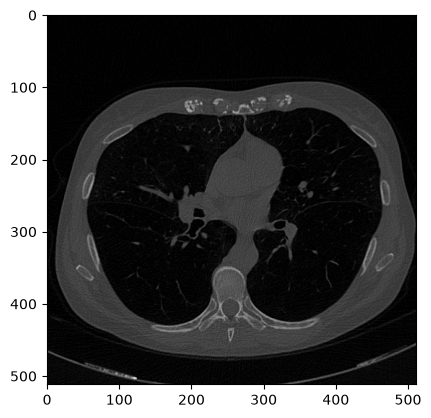

In [3]:
import matplotlib.pyplot as plt 
plt.imshow(scan[scan.shape[0]//2], cmap='gray') 
plt.show()

## Explorar as características subjetivas dos nódulos

Objetivo: perceber a estrutura do ficheiro `chars_trainNodules.csv`, que contém as classificações subjetivas de cada nódulo feitas pelos radiólogos (incluindo a malignidade), antes de o combinarmos com as coordenadas

In [4]:
import pandas as pd

In [5]:
df = pd.read_csv('data/chars_trainNodules.csv')

In [6]:
df.head()

,LNDbID,RadID,FindingID,calcification,internalStructure,lobulation,malignancy,margin,sphericity,spiculation,subtlety
0,1.0,1.0,1.0,6.0,1.0,1.0,2.0,4.0,2.0,2.0,5.0
1,1.0,1.0,2.0,6.0,1.0,1.0,2.0,4.0,2.0,1.0,3.0
2,1.0,2.0,1.0,3.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0
3,1.0,3.0,1.0,5.0,1.0,2.0,2.0,3.0,4.0,3.0,4.0
4,2.0,1.0,1.0,6.0,1.0,1.0,1.0,5.0,3.0,1.0,5.0


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1527 entries, 0 to 1526
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   LNDbID             1527 non-null   float64
 1   RadID              1527 non-null   float64
 2   FindingID          1527 non-null   float64
 3   calcification      1527 non-null   float64
 4   internalStructure  1527 non-null   float64
 5   lobulation         1527 non-null   float64
 6   malignancy         1527 non-null   float64
 7   margin             1527 non-null   float64
 8   sphericity         1527 non-null   float64
 9   spiculation        1527 non-null   float64
 10  subtlety           1527 non-null   float64
dtypes: float64(11)
memory usage: 131.4 KB


**Conclusões:**
- O ficheiro tem `1527` linhas e nenhum valor em falta logo os dados limpos
- Cada linha corresponde a um achado (`FindingID`) marcado por um radiólogo (`RadID`) num scan (`LNDbID`) ou seja, **não está fundido** entre radiólogos
- Inclui a coluna `malignancy` (escala 1-5), além de outras características (calcificação, lobulação, margem, esfericidade, espiculação, subtileza, estrutura interna)
- Não tem coordenadas (x, y, z): para as obter é preciso ligar este ficheiro ao `trainNodules.csv`.

## Localizar um nódulo real no scan

Objetivo: validar o pipeline completo do princípio ao fim desde ler as coordenadas de um nódulo do `trainNodules.csv` (dadas em coordenadas do mundo, em mm) e convertê-las para coordenadas de imagem (índices de pixel/corte), usando a origem e a matriz de transformação do scan

In [9]:
from utils import convertToImgCoord, getImgWorldTransfMats
import numpy as np

# ler o csv de anotações
nodules = pd.read_csv(r'c:\LNDb_csvs\trainNodules.csv')

nod1 = nodules[nodules['LNDbID'] == 1].iloc[0]
xyz_world = np.array([nod1['x'], nod1['y'], nod1['z']])

transfmat_toimg, transfmat_toworld = getImgWorldTransfMats(spacing, transfmat)
xyz_img = convertToImgCoord(xyz_world, origin, transfmat_toimg)
print(xyz_img)

[187. 313. 260.]


**Conclusão:** o resultado `[187, 313, 260]` está na ordem `(x, y, z)`. Questão importante: o array `scan` está indexado na ordem `(z, y, x)` pois há uma diferença de convenção entre SimpleITK e NumPy que não nos podemos esquecer! Os valores fazem sentido: porque estão dentro dos limites do volume (`328×512×512`)

## Confirmação visual da conversão de coordenadas

Objetivo: Mostrar o corte exato onde o nódulo foi anotado, com uma marca vermelha na posição calculada

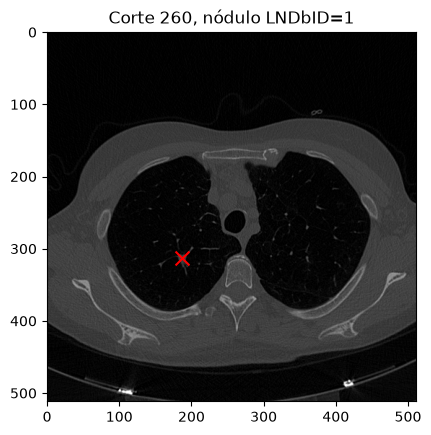

In [10]:
z_slice = int(xyz_img[2])  # o terceiro valor, correspondente ao corte
y_row = int(xyz_img[1])
x_col = int(xyz_img[0])

plt.imshow(scan[z_slice], cmap='gray')
plt.scatter(x_col, y_row, c='red', marker='x', s=100)  # marca a posição do nódulo
plt.title(f'Corte {z_slice}, nódulo LNDbID=1')
plt.show()

## Extrair um cubo (patch) à volta do nódulo

Objetivo: testar a função `extractCube`, que recorta e reamostra uma região fixa à volta de uma coordenada: podemos dps usar como entrada do modelo

(80, 80, 80)


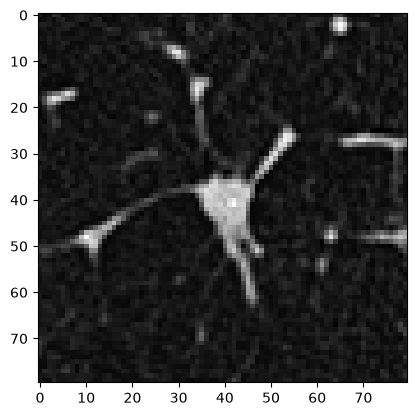

In [11]:
from utils import extractCube 
cube = extractCube(scan, spacing, xyz_img) 
print(cube.shape) 
plt.imshow(cube[cube.shape[0]//2], cmap='gray') 
plt.show() 

**Conclusão:** o cubo extraído tem `80×80×80` voxels, um tamanho fixo definido por omissão na função (correspondente a uma janela de ~51mm de lado antes de reamostrar). O corte central mostra o nódulo bem centrado

## Juntar coordenadas e características numa só tabela

Objetivo: fazer o *merge* entre `trainNodules.csv` (coordenadas) e `chars_trainNodules.csv` (características, incluindo malignidade), usando `LNDbID`, `RadID` e `FindingID` como chave comum.

In [12]:
nodules = pd.read_csv(r'c:\LNDb_csvs\trainNodules.csv')
chars = pd.read_csv(r'data/chars_trainNodules.csv')  # ajustem o caminho se necessário

merged = pd.merge(
    nodules, chars,
    on=['LNDbID', 'RadID', 'FindingID'],
    how='left'
)

print(merged.shape)
merged.head()

(1527, 17)


,LNDbID,RadID,FindingID,x,y,z,Nodule,Volume,Text,calcification,internalStructure,lobulation,malignancy,margin,sphericity,spiculation,subtlety
0,1,1,1,-44.608398,-119.073242,-37.5,1,440.908794,5,6.0,1.0,1.0,2.0,4.0,2.0,2.0,5.0
1,1,1,2,25.852539,-126.969727,-45.5,1,152.381031,4,6.0,1.0,1.0,2.0,4.0,2.0,1.0,3.0
2,1,2,1,-44.000977,-118.465820,-37.5,1,56.820045,5,3.0,1.0,1.0,2.0,2.0,2.0,2.0,2.0
3,1,3,1,-44.000977,-119.680664,-37.5,1,169.353252,5,5.0,1.0,2.0,2.0,3.0,4.0,3.0,4.0
4,2,1,1,88.895508,-123.625977,-129.5,1,339.187950,5,6.0,1.0,1.0,1.0,5.0,3.0,1.0,5.0


**Conclusão:** o número de linhas mantém-se em 1527. A tabela resultante tem `17` colunas e já contém tudo o que precisamos por observação: coordenadas, categoria e características subjetivas

## Função reutilizável

Para não repetir manualmente o processo de leitura e conversão de coordenadas para cada scan, podemos empacotar essa lógica numa função que recebe um LNDbID e devolve o scan já lido e a tabela dos seus nódulos com as coordenadas de imagem calculadas

In [13]:
import os

def ler_scan_e_nodulos(lndb_id, pasta_scans, tabela_nodulos):
    """
    Lê o scan de um LNDbID e devolve o array, metadados e os nódulos desse scan
    já convertidos para coordenadas de imagem.
    """
    caminho_mhd = os.path.join(pasta_scans, f'LNDb-{lndb_id:04d}.mhd')
    scan, spacing, origin, transfmat = readMhd(caminho_mhd)

    transfmat_toimg, transfmat_toworld = getImgWorldTransfMats(spacing, transfmat)

    nods_scan = tabela_nodulos[tabela_nodulos['LNDbID'] == lndb_id].copy()

    coords_img = []
    for _, linha in nods_scan.iterrows():
        xyz_world = np.array([linha['x'], linha['y'], linha['z']])
        xyz_img = convertToImgCoord(xyz_world, origin, transfmat_toimg)
        coords_img.append(xyz_img)

    nods_scan['x_img'] = [c[0] for c in coords_img]
    nods_scan['y_img'] = [c[1] for c in coords_img]
    nods_scan['z_img'] = [c[2] for c in coords_img]

    return scan, spacing, origin, nods_scan

## Validar a função com o caso já conhecido

Testamos a função com `LNDbID=1`, o mesmo caso testado manualmente antes, para confirmar que devolve o mesmo resultado

In [14]:
scan1, spacing1, origin1, nods1 = ler_scan_e_nodulos(1, r'C:\LNDb_data0', merged)
print(nods1[['LNDbID', 'RadID', 'FindingID', 'x_img', 'y_img', 'z_img']])

   LNDbID  RadID  FindingID  x_img  y_img  z_img
0       1      1          1  187.0  313.0  260.0
1       1      1          2  303.0  300.0  252.0
2       1      2          1  188.0  314.0  260.0
3       1      3          1  188.0  312.0  260.0


**Conclusão:** a 1ª linha devolve os msms resultados que antes logo está correto. Reparamos também que este scan tem `4` observações no total, marcados por `3` radiólogos diferentes (nem todos os radiólogos marcaram os mesmos nódulos)

## Inventariar os scans disponíveis

Como ainda só tenho o `data0.rar` descarregado comecei por identificar quais LNDbID têm mesmo o .mhd correspondente na pasta local, para não tentarmos processar scans que ainda não temos

In [17]:
# descobrir que LNDbIDs existem realmente na pasta descarregada
ficheiros_mhd = [f for f in os.listdir(r'C:\LNDb_data0') if f.endswith('.mhd')]
ids_disponiveis = sorted([int(f.replace('LNDb-', '').replace('.mhd', '')) for f in ficheiros_mhd])
print(f'{len(ids_disponiveis)} scans disponíveis: {ids_disponiveis[:10]}...')

43 scans disponíveis: [1, 2, 3, 4, 5, 7, 8, 10, 11, 13]...


**Conclusão:** há `43` scans disponíveis localmente, de um total de `294` no LNDb completo (~15%). É suficiente para validar o pipeline, mas a tabela final ainda está incompleta

## Aplicar a todos os scans disponíveis



In [16]:
todas_as_tabelas = []

for lndb_id in ids_disponiveis:
    try:
        _, _, _, nods = ler_scan_e_nodulos(lndb_id, r'C:\LNDb_data0', merged)
        todas_as_tabelas.append(nods)
    except Exception as e:
        print(f'Erro no LNDbID {lndb_id}: {e}')

tabela_final = pd.concat(todas_as_tabelas, ignore_index=True)
print(tabela_final.shape)

(377, 20)


**Conclusão:** obtivemos 377 linhas de nódulos a partir dos 43 scans (uma média de ~8,8 observações por scan, contando cada radiólogo separadamente)

## Exportar no esquema combinado com o grupo

Verificar se mantemos ou alteramos o esquema da tabela

In [18]:
tabela_gerada = pd.DataFrame({
    'dataset': 'LNDb',
    'scan_id': tabela_final['LNDbID'],
    'nodulo_id': tabela_final['FindingID'],
    'x': tabela_final['x_img'],
    'y': tabela_final['y_img'],
    'z': tabela_final['z_img'],
    'diametro_mm': None,  # LNDb dá volume, não diâmetro direto — ver nota abaixo
    'categoria': tabela_final['Nodule'],
    'malignidade_rating': tabela_final.get('malignancy'),  # confirmem o nome exato da coluna
    'radiologo_id': tabela_final['RadID'],
})

tabela_gerada.to_csv('lndb_processado.csv', index=False)
print('Guardado com sucesso:', tabela_gerada.shape)

Guardado com sucesso: (377, 10)


## Calcular o diâmetro equivalente a partir do volume

O LNDb não dá o diâmetro do nódulo diretamente, apenas o volume. Podemos usar a função nodEqDiam (fornecida no `readNoduleList.py`), que assume o nódulo como uma esfera e calcula o diâmetro equivalente a partir do volume:

**Diâmetro equivalente:**
$$d = 2 \left( \frac{3V}{4\pi} \right)^{1/3}$$

onde V representa o volume do nódulo em mm³, tal como vem no CSV.

In [19]:
from readNoduleList import nodEqDiam
tabela_gerada['diametro_mm'] = tabela_final['Volume'].apply(nodEqDiam)

Voltar a guardar o csv